## Análise de Similaridade Textual (STS)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
import plotly.express as px
from sklearn.metrics import mean_squared_error
from deep_translator import GoogleTranslator

plt.style.use('ggplot')
sns.set_palette("dark")

In [2]:
# Função para estilização de DataFrames
def styled_examples(df):
    return df.style.set_properties(**{
        'background-color': '#f8f9fa',
        'border': '1px solid #dee2e6',
        'padding': '5px',
        'color': '#212529'
    }).set_table_styles([{
        'selector': 'th',
        'props': [('background-color', '#343a40'), ('color', 'white')]
    }])

In [3]:
# Traduzir sentenças para português
def translate_sentence(sentence):
    try:
        return GoogleTranslator(source='en', target='pt').translate(sentence)
    except Exception as e:
        print(f"Erro ao traduzir: {e}")
        return sentence  # Retorna original se houver erro

### Carregamento de Dados

In [4]:
def load_sts_data():
    pretrain_dev = pd.read_csv(f'../predictions/sts_v1/pretrain-sts-dev-output.csv', sep='\t')
    finetune_dev = pd.read_csv(f'../predictions/sts_v1/finetune-sts-dev-output.csv', sep='\t')
    
    merged_dev = pretrain_dev.merge(
        finetune_dev, 
        on='id', 
        suffixes=('_pretrain', '_finetune')
    )
    return merged_dev

sts_dev = load_sts_data()
sts_dev['True_Similarity'] = sts_dev['True_Similarity_pretrain']
sts_dev.drop(columns=['True_Similarity_pretrain', 'True_Similarity_finetune'], inplace=True)
sts_dev.head()


,id,Predicted_Similarity_pretrain,Predicted_Similarity_finetune,True_Similarity
0,876d0172eef5db7776e39c5de,2.5238,1.5010,1.0
1,e8336dc096adaf2de4e8e9425,2.2983,4.8767,4.6
2,6b73f3755d3f2a1906e25bcc2,2.1032,2.9013,2.5
3,1047dcaead3ca64fe7bb22637,1.9762,2.1910,3.2
4,30f3274a6f8bc1698fb90cd7b,1.7195,3.4825,3.2


In [5]:
sts_sentences = pd.read_csv('../data/sts-dev.csv', sep='\t')
sts_dev = sts_dev.merge(sts_sentences, on='id')

## Análise Quantitativa

In [6]:
# Calcular métricas
def calculate_metrics(true, pred):
    pearson, _ = pearsonr(true, pred)
    mse = mean_squared_error(true, pred)
    return pearson, mse

pearson_pretrain, mse_pretrain = calculate_metrics(
    sts_dev['True_Similarity'], sts_dev['Predicted_Similarity_pretrain']
)

pearson_finetune, mse_finetune = calculate_metrics(
    sts_dev['True_Similarity'], sts_dev['Predicted_Similarity_finetune']
)

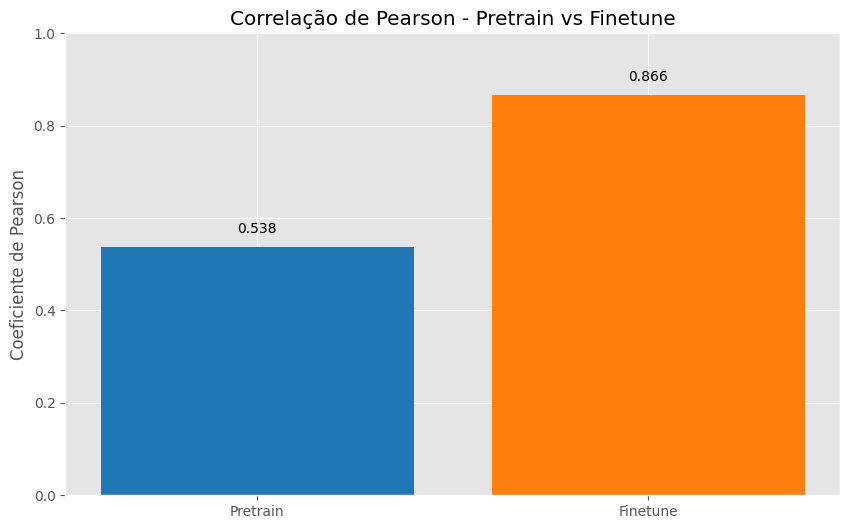

In [7]:
# Plotar comparação de Pearson
plt.figure(figsize=(10,6))
plt.bar(['Pretrain', 'Finetune'], [pearson_pretrain, pearson_finetune], 
        color=['#1f77b4', '#ff7f0e'])
plt.title('Correlação de Pearson - Pretrain vs Finetune')
plt.ylabel('Coeficiente de Pearson')
plt.ylim(0, 1)
for i, v in enumerate([pearson_pretrain, pearson_finetune]):
    plt.text(i, v + 0.03, f"{v:.3f}", ha='center')
plt.show()

## Análise de Erros

In [8]:
# Calcular diferenças absolutas
sts_dev['error_pretrain'] = abs(sts_dev['True_Similarity'] - sts_dev['Predicted_Similarity_pretrain'])
sts_dev['error_finetune'] = abs(sts_dev['True_Similarity'] - sts_dev['Predicted_Similarity_finetune'])

### Distribuição de Erros

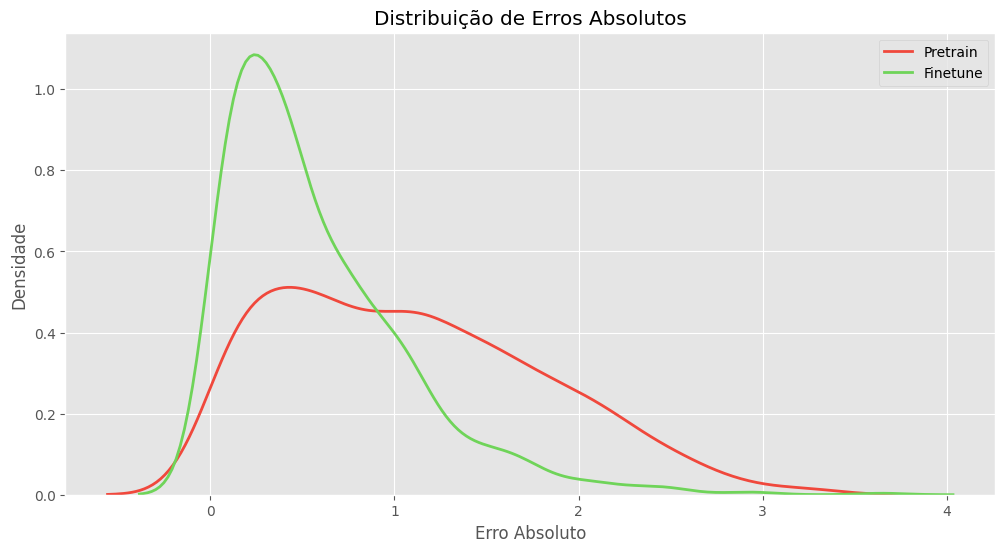

In [9]:
plt.figure(figsize=(12,6))
sns.kdeplot(sts_dev['error_pretrain'], label='Pretrain', linewidth=2, color='#f0483c')
sns.kdeplot(sts_dev['error_finetune'], label='Finetune', linewidth=2, color='#6fd459')
plt.title('Distribuição de Erros Absolutos')
plt.xlabel('Erro Absoluto')
plt.ylabel('Densidade')
plt.legend()
plt.show()

## Exemplos de Melhoria

In [10]:
# Encontrar exemplos com maior melhoria
sts_dev['improvement'] = sts_dev['error_pretrain'] - sts_dev['error_finetune']
top_improvements = sts_dev.nlargest(5, 'improvement')

In [11]:
# traduzir sentenças
top_improvements['sentence1'] = top_improvements['sentence1'].apply(translate_sentence)
top_improvements['sentence2'] = top_improvements['sentence2'].apply(translate_sentence)

# Exibir tabela formatada
styled_examples(top_improvements[[
    'sentence1', 'sentence2', 'True_Similarity', 
    'Predicted_Similarity_pretrain', 'Predicted_Similarity_finetune'
]])

,sentence1,sentence2,True_Similarity,Predicted_Similarity_pretrain,Predicted_Similarity_finetune
324,O menino está tocando piano.,Um menino toca piano.,5.000000,1.890300,4.778200
89,Um menino está empurrando outro menino em um balanço.,Um menino está empurrando outro menino no balanço.,4.800000,1.937300,4.783800
275,Um close de uma ovelha com a língua de fora.,Imagem em close de uma ovelha com a língua de fora.,5.000000,2.030200,4.872000
206,Estou de acordo com o uso MÉDICO!,EU CONCORDO COM O USO MÉDICO!!,5.000000,2.182600,4.985600
114,Não vejo por que haveria algum problema com isso.,Não vejo por que isso poderia ser um problema.,5.000000,1.757800,4.489800


## Visualização Interativa e Análise de Erros

In [12]:
# Gráfico de dispersão 3D interativo
fig = px.scatter_3d(
    sts_dev.sample(500),
    x='Predicted_Similarity_pretrain',
    y='Predicted_Similarity_finetune',
    z='True_Similarity',
    color='error_finetune',
    hover_data=['sentence1', 'sentence2'], 
    title='Relação entre Previsões e Similaridade Real'
)
fig.update_layout(scene=dict(
    xaxis_title='Pretrain',
    yaxis_title='Finetune',
    zaxis_title='Real'
))
fig.show()


<Axes: xlabel='Predicted_Similarity_pretrain', ylabel='True_Similarity'>

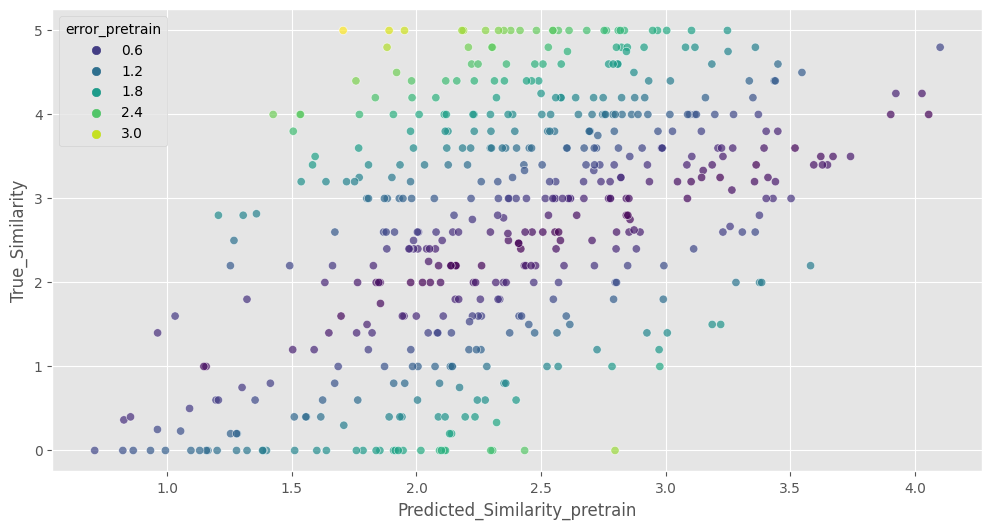

In [13]:
# Gráfico 2D entre previsões do modelo pré-treinado e similaridade real
plt.figure(figsize=(12,6))
sns.scatterplot(
    data=sts_dev.sample(500),
    x='Predicted_Similarity_pretrain',
    y='True_Similarity',
    hue='error_pretrain',
    palette='viridis',
    alpha=0.7
)

<Axes: xlabel='Predicted_Similarity_finetune', ylabel='True_Similarity'>

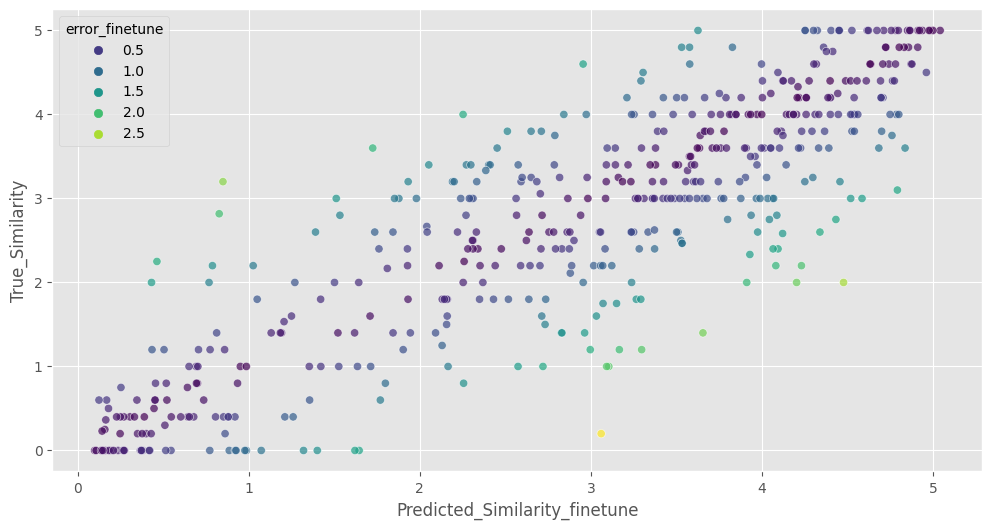

In [14]:
# Gráfico 2D entre previsões do modelo fine-tuned e similaridade real
plt.figure(figsize=(12,6))
sns.scatterplot(
    data=sts_dev.sample(500),
    x='Predicted_Similarity_finetune',
    y='True_Similarity',
    hue='error_finetune',
    palette='viridis',
    alpha=0.7
)